<a href="https://colab.research.google.com/github/Arshad-pf/verbose-octo-pancake/blob/main/cv_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))


TensorFlow version: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

print("NumPy:", np.__version__)
print("Matplotlib:", plt.matplotlib.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))


NumPy: 2.1.3
Matplotlib: 3.10.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [4]:

import tensorflow as tf

dataset_url = (
    "https://storage.googleapis.com/"
    "download.tensorflow.org/example_images/flower_photos.tgz"
)

print("TensorFlow is ready to load image datasets.")
print("Our target dataset: PlantVillage")


TensorFlow is ready to load image datasets.
Our target dataset: PlantVillage


In [7]:
pip -q install datasets

In [9]:


from datasets import load_dataset

dataset = load_dataset("mohanty/PlantVillage")

print(dataset)
print("\nTraining samples:", len(dataset["train"]))
print("Test samples:", len(dataset["test"]))
print("\nFeatures:", dataset["train"].column_names)



ValueError: BuilderConfig 'color' not found. Available: ['default']

In [10]:

!pip -q install tensorflow-datasets


In [11]:

import tensorflow_datasets as tfds

print(tfds.builder("plant_village").info)


tfds.core.DatasetInfo(
    name='plant_village',
    full_name='plant_village/1.0.2',
    description="""
    The PlantVillage dataset consists of 54303 healthy and unhealthy leaf images
    divided into 38 categories by species and disease.
    
    NOTE: The original dataset is not available from the original source
    (plantvillage.org), therefore we get the unaugmented dataset from a paper that
    used that dataset and republished it. Moreover, we dropped images with
    Background_without_leaves label, because these were not present in the original
    dataset.
    
    Original paper URL: https://arxiv.org/abs/1511.08060 Dataset URL:
    https://data.mendeley.com/datasets/tywbtsjrjv/1
    """,
    homepage='https://arxiv.org/abs/1511.08060',
    data_dir='/root/tensorflow_datasets/plant_village/1.0.2',
    file_format=tfrecord,
    download_size=Unknown size,
    dataset_size=Unknown size,
    features=FeaturesDict({
        'image': Image(shape=(None, None, 3), dtype=uint8),
 

In [12]:

import tensorflow_datasets as tfds

builder = tfds.builder("plant_village")

print("Available splits:", builder.info.splits)
print("Download size:", builder.info.download_size)

builder.download_and_prepare()

print("Dataset download and preparation complete!")
print("Available splits:", builder.info.splits)


Available splits: {}
Download size: Unknown size


ModuleNotFoundError: No module named 'importlib_resources'

In [13]:

%pip install -q importlib-resources


In [14]:

import tensorflow as tf
import tensorflow_datasets as tfds

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

builder = tfds.builder("plant_village")
builder.download_and_prepare()

print("Dataset prepared!")
print(builder.info.splits)


TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

DownloadError: Failed to get url https://data.mendeley.com/public-files/datasets/tywbtsjrjv/files/d5652a28-c1d8-4b76-97f3-72fb80f94efc/file_downloaded. HTTP code: 403.

In [15]:

import requests

url = "https://api.github.com/repos/spMohanty/PlantVillage-Dataset"

response = requests.get(url, timeout=20)

print("HTTP status:", response.status_code)

if response.ok:
    info = response.json()
    print("Repository:", info["full_name"])
    print("Default branch:", info["default_branch"])
else:
    print(response.text[:500])


HTTP status: 200
Repository: spMohanty/PlantVillage-Dataset
Default branch: master


In [16]:
import requests

url = "https://api.github.com/repos/spMohanty/PlantVillage-Dataset/contents/raw/color"
response = requests.get(url, timeout=30)

print("HTTP status:", response.status_code)

if response.ok:
    folders = response.json()
    tomato_classes = [
        item["name"] for item in folders
        if item["type"] == "dir" and item["name"].startswith("Tomato___")
    ]
    print("Tomato classes found:", len(tomato_classes))
    for name in tomato_classes:
        print(name)
else:
    print(response.text[:500])

HTTP status: 200
Tomato classes found: 10
Tomato___Bacterial_spot
Tomato___Early_blight
Tomato___Late_blight
Tomato___Leaf_Mold
Tomato___Septoria_leaf_spot
Tomato___Spider_mites Two-spotted_spider_mite
Tomato___Target_Spot
Tomato___Tomato_Yellow_Leaf_Curl_Virus
Tomato___Tomato_mosaic_virus
Tomato___healthy


In [17]:
import requests

classes = [
    "Tomato___healthy",
    "Tomato___Early_blight",
    "Tomato___Late_blight"
]

base_url = (
    "https://api.github.com/repos/"
    "spMohanty/PlantVillage-Dataset/contents/raw/color"
)

for class_name in classes:
    url = f"{base_url}/{class_name}"
    response = requests.get(url, timeout=30)

    if response.ok:
        images = [
            item for item in response.json()
            if item["type"] == "file"
            and item["name"].lower().endswith((".jpg", ".jpeg", ".png"))
        ]
        print(f"{class_name}: {len(images)} images")
    else:
        print(f"{class_name}: HTTP {response.status_code}")

Tomato___healthy: 1000 images
Tomato___Early_blight: 1000 images
Tomato___Late_blight: 1000 images


In [18]:
import os
import requests
from concurrent.futures import ThreadPoolExecutor, as_completed

BASE_URL = (
    "https://api.github.com/repos/"
    "spMohanty/PlantVillage-Dataset/contents/raw/color"
)

DATA_DIR = "/content/tomato_data"
SAMPLES_PER_CLASS = 300

classes = [
    "Tomato___healthy",
    "Tomato___Early_blight",
    "Tomato___Late_blight"
]

os.makedirs(DATA_DIR, exist_ok=True)

def download_image(args):
    class_name, item = args
    image_url = item["download_url"]
    filename = item["name"]
    folder = os.path.join(DATA_DIR, class_name)
    path = os.path.join(folder, filename)

    if os.path.exists(path):
        return True

    try:
        r = requests.get(image_url, timeout=30)
        if r.ok and r.headers.get("Content-Type", "").startswith("image/"):
            with open(path, "wb") as f:
                f.write(r.content)
            return True
    except requests.RequestException:
        pass

    return False

for class_name in classes:
    print(f"\nPreparing {class_name}...")
    folder = os.path.join(DATA_DIR, class_name)
    os.makedirs(folder, exist_ok=True)

    response = requests.get(
        f"{BASE_URL}/{class_name}",
        timeout=30
    )
    response.raise_for_status()

    files = [
        item for item in response.json()
        if item["type"] == "file"
        and item["name"].lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    # Deterministically select a sample from the available filenames.
    files = sorted(files, key=lambda item: item["name"])[:SAMPLES_PER_CLASS]

    with ThreadPoolExecutor(max_workers=8) as executor:
        results = list(executor.map(
            download_image,
            [(class_name, item) for item in files]
        ))

    downloaded = sum(results)
    print(f"Downloaded: {downloaded}/{SAMPLES_PER_CLASS}")

print("\nDownload step finished.")


Preparing Tomato___healthy...
Downloaded: 300/300

Preparing Tomato___Early_blight...
Downloaded: 300/300

Preparing Tomato___Late_blight...
Downloaded: 300/300

Download step finished.


In [19]:
import os
import random
import shutil

random.seed(42)

SPLIT_DIR = "/content/tomato_split"
SPLITS = {
    "train": 0.70,
    "val": 0.15,
    "test": 0.15
}

# Clean up a previous split if this cell is rerun.
if os.path.exists(SPLIT_DIR):
    shutil.rmtree(SPLIT_DIR)

for split in SPLITS:
    for class_name in classes:
        os.makedirs(
            os.path.join(SPLIT_DIR, split, class_name),
            exist_ok=True
        )

for class_name in classes:
    source = os.path.join(DATA_DIR, class_name)
    filenames = sorted([
        f for f in os.listdir(source)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ])

    random.shuffle(filenames)

    n = len(filenames)
    n_train = int(n * 0.70)
    n_val = int(n * 0.15)

    split_files = {
        "train": filenames[:n_train],
        "val": filenames[n_train:n_train + n_val],
        "test": filenames[n_train + n_val:]
    }

    for split, files in split_files.items():
        for filename in files:
            shutil.copy2(
                os.path.join(source, filename),
                os.path.join(SPLIT_DIR, split, class_name, filename)
            )

print("Dataset split complete!\n")

for split in SPLITS:
    print(f"{split.upper()}:")
    for class_name in classes:
        folder = os.path.join(SPLIT_DIR, split, class_name)
        count = len(os.listdir(folder))
        print(f"  {class_name}: {count}")

Dataset split complete!

TRAIN:
  Tomato___healthy: 210
  Tomato___Early_blight: 210
  Tomato___Late_blight: 210
VAL:
  Tomato___healthy: 45
  Tomato___Early_blight: 45
  Tomato___Late_blight: 45
TEST:
  Tomato___healthy: 45
  Tomato___Early_blight: 45
  Tomato___Late_blight: 45


In [20]:
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(SPLIT_DIR, "train"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True,
    seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(SPLIT_DIR, "val"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(SPLIT_DIR, "test"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

class_names = train_ds.class_names

print("\nClass order:")
for i, name in enumerate(class_names):
    print(i, ":", name)

# Improve input pipeline performance
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

print("\nDatasets are ready!")

Found 630 files belonging to 3 classes.
Found 135 files belonging to 3 classes.
Found 135 files belonging to 3 classes.

Class order:
0 : Tomato___Early_blight
1 : Tomato___Late_blight
2 : Tomato___healthy

Datasets are ready!


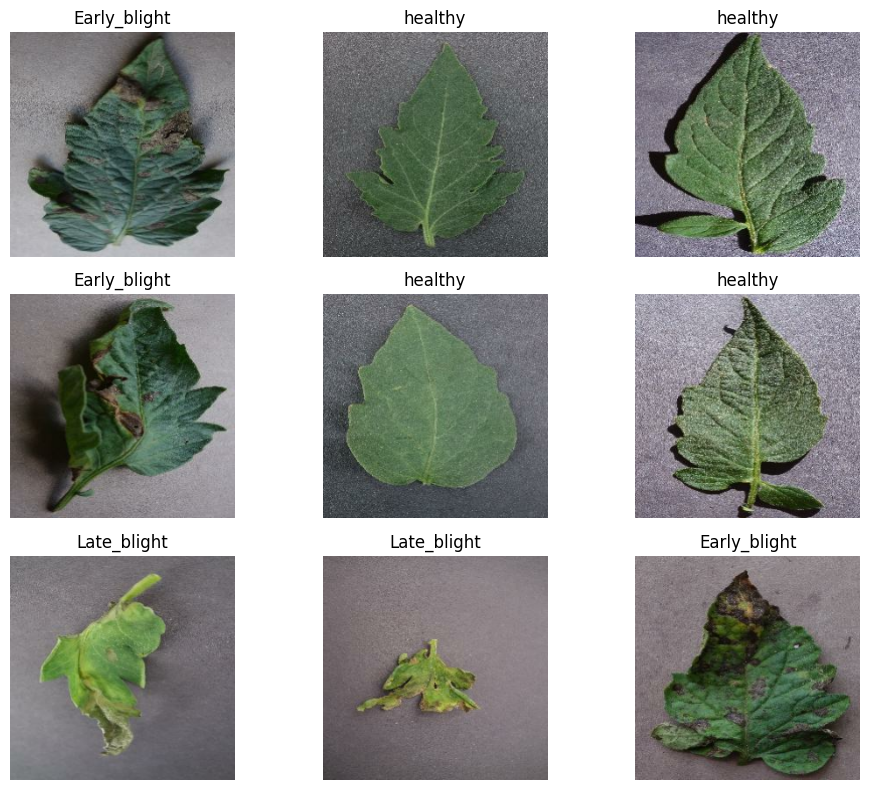

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

for images, labels in train_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i])].replace("Tomato___", ""))
        plt.axis("off")

plt.tight_layout()
plt.show()

In [22]:
import tensorflow as tf
from tensorflow.keras import layers, models

# Load pretrained MobileNetV2
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze pretrained layers for initial training
base_model.trainable = False

# Build our classifier
inputs = layers.Input(shape=(224, 224, 3))

# MobileNetV2 preprocessing maps pixels to [-1, 1]
x = tf.keras.applications.mobilenet_v2.preprocess_input(inputs)

x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)

outputs = layers.Dense(
    len(class_names),
    activation="softmax"
)(x)

model = models.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [23]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "/content/best_tomato_model.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks
)

Epoch 1/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 25s 716ms/step - accuracy: 0.5365 - loss: 0.9667 - val_accuracy: 0.8148 - val_loss: 0.5411
Epoch 2/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 70ms/step - accuracy: 0.8048 - loss: 0.4995 - val_accuracy: 0.8593 - val_loss: 0.3843
Epoch 3/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 67ms/step - accuracy: 0.8603 - loss: 0.3725 - val_accuracy: 0.8815 - val_loss: 0.3041
Epoch 4/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 70ms/step - accuracy: 0.8873 - loss: 0.3073 - val_accuracy: 0.9037 - val_loss: 0.2757
Epoch 5/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 67ms/step - accuracy: 0.8937 - loss: 0.2804 - val_accuracy: 0.8963 - val_loss: 0.2455
Epoch 6/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 66ms/step - accuracy: 0.9254 - loss: 0.2371 - val_accuracy: 0.9111 - val_loss: 0.2277
Epoch 7/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 68ms/step - accuracy: 0.9317 - loss: 0.2143 - val_accuracy: 0.9185 - val_loss: 0.2108
Epoch 8/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - accuracy: 0.9222 - loss: 0.2057 - val_accuracy: 0.9185 -

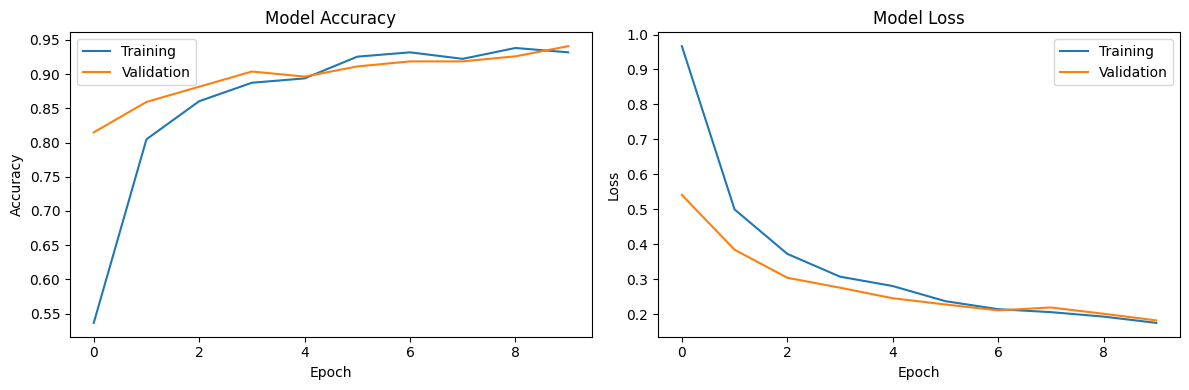

In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [25]:
test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)

print(f"\nTest Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.8815 - loss: 0.3090

Test Accuracy: 88.15%
Test Loss: 0.3090


In [26]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

y_probs = model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_probs, axis=1)

print(classification_report(
    y_true,
    y_pred,
    labels=range(len(class_names)),
    target_names=class_names,
    zero_division=0
))

5/5 ━━━━━━━━━━━━━━━━━━━━ 8s 811ms/step
                       precision    recall  f1-score   support

Tomato___Early_blight       0.85      0.78      0.81        45
 Tomato___Late_blight       0.80      0.87      0.83        45
     Tomato___healthy       1.00      1.00      1.00        45

             accuracy                           0.88       135
            macro avg       0.88      0.88      0.88       135
         weighted avg       0.88      0.88      0.88       135



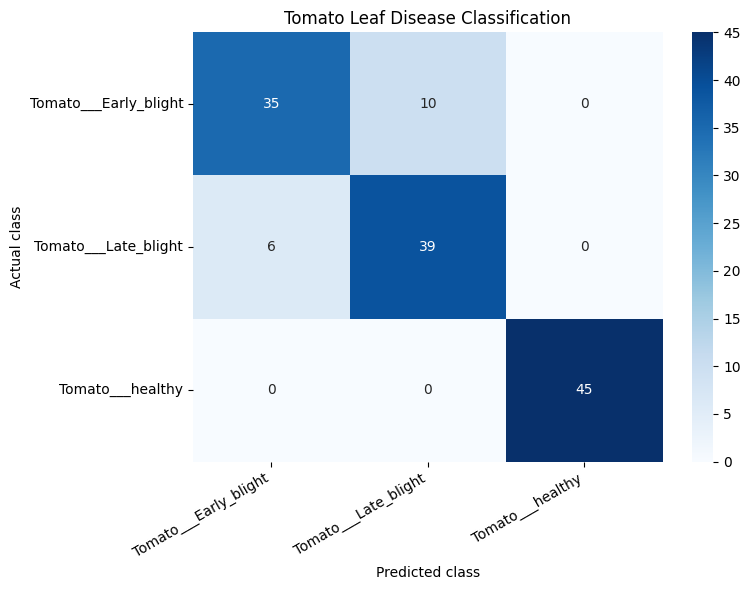

In [27]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=range(len(class_names))
)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.title("Tomato Leaf Disease Classification")
plt.xticks(rotation=30, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [28]:
model.save("/content/tomato_disease_model.keras")
print("Model saved successfully!")

Model saved successfully!


Incorrect predictions: 16


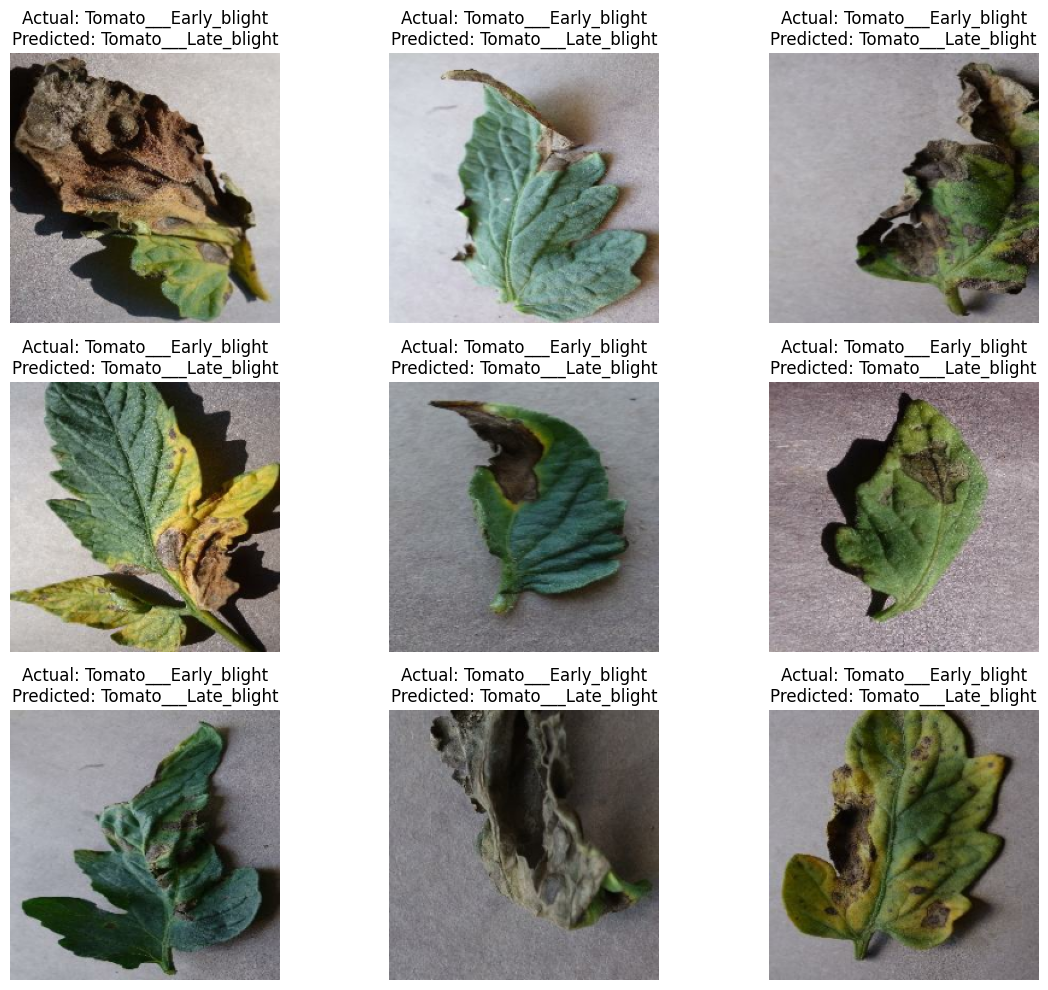

In [29]:
import numpy as np
import matplotlib.pyplot as plt

wrong_indices = np.where(y_true != y_pred)[0]

print("Incorrect predictions:", len(wrong_indices))

# Show up to 9 incorrect examples
plt.figure(figsize=(12, 10))

for plot_i, idx in enumerate(wrong_indices[:9]):
    image_batch = list(test_ds.unbatch().skip(int(idx)).take(1))
    if not image_batch:
        continue

    image, label = image_batch[0]
    probs = y_probs[idx]

    plt.subplot(3, 3, plot_i + 1)
    plt.imshow(image.numpy().astype("uint8"))
    plt.title(
        f"Actual: {class_names[int(label)]}\n"
        f"Predicted: {class_names[int(np.argmax(probs))]}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

In [30]:
# Keep the pretrained model's earlier features frozen.
base_model.trainable = True

# Unfreeze only the later layers.
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep Batch Normalization layers frozen for stability.
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

fine_tune_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "/content/best_tomato_finetuned.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

fine_tune_history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    callbacks=fine_tune_callbacks
)

Epoch 1/8
20/20 ━━━━━━━━━━━━━━━━━━━━ 24s 647ms/step - accuracy: 0.9492 - loss: 0.1443 - val_accuracy: 0.9407 - val_loss: 0.1532
Epoch 2/8
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - accuracy: 0.9651 - loss: 0.1035 - val_accuracy: 0.9111 - val_loss: 0.1766
Epoch 3/8
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 73ms/step - accuracy: 0.9683 - loss: 0.0926 - val_accuracy: 0.9407 - val_loss: 0.1376
Epoch 4/8
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 72ms/step - accuracy: 0.9825 - loss: 0.0665 - val_accuracy: 0.9481 - val_loss: 0.1224
Epoch 5/8
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 74ms/step - accuracy: 0.9905 - loss: 0.0508 - val_accuracy: 0.9481 - val_loss: 0.1197
Epoch 6/8
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - accuracy: 0.9873 - loss: 0.0466 - val_accuracy: 0.9481 - val_loss: 0.1277
Epoch 7/8
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 51ms/step - accuracy: 0.9873 - loss: 0.0418 - val_accuracy: 0.9481 - val_loss: 0.1258
Epoch 8/8
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 84ms/step - accuracy: 0.9984 - loss: 0.0284 - val_accuracy: 0.9556 - val_los

In [31]:
test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)
print(f"Fine-tuned test accuracy: {test_accuracy * 100:.2f}%")

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.9111 - loss: 0.2679
Fine-tuned test accuracy: 91.11%


In [32]:
import json

MODEL_PATH = "/content/tomato_disease_model.keras"
LABELS_PATH = "/content/tomato_class_names.json"

model.save(MODEL_PATH)

with open(LABELS_PATH, "w") as f:
    json.dump(class_names, f)

print("Model saved:", MODEL_PATH)
print("Class labels:", class_names)

Model saved: /content/tomato_disease_model.keras
Class labels: ['Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___healthy']


Saving 360_F_1244777686_APGlUk2ralLjKTnihzkBPaH0WUEp5dt2.jpg to 360_F_1244777686_APGlUk2ralLjKTnihzkBPaH0WUEp5dt2.jpg


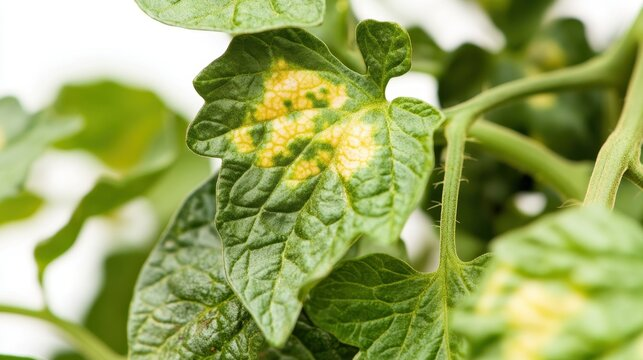


Predicted class: Late_blight
Model confidence: 94.19%

All class scores:
Early_blight: 5.81%
Late_blight: 94.19%
healthy: 0.00%


In [33]:
from google.colab import files
from IPython.display import display
from PIL import Image
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

uploaded = files.upload()

for filename in uploaded:
    image = Image.open(filename).convert("RGB")
    display(image)

    resized = image.resize((224, 224))
    image_array = np.array(resized, dtype=np.float32)
    image_array = np.expand_dims(image_array, axis=0)

    probabilities = model.predict(image_array, verbose=0)[0]
    predicted_index = int(np.argmax(probabilities))

    print("\nPredicted class:",
          class_names[predicted_index].replace("Tomato___", ""))

    print(f"Model confidence: {probabilities[predicted_index] * 100:.2f}%")
    print("\nAll class scores:")

    for name, score in zip(class_names, probabilities):
        print(f"{name.replace('Tomato___', '')}: {score * 100:.2f}%")

In [34]:
!pip -q install gradio

In [35]:
import os
import tensorflow as tf

MODEL_PATH = "/content/tomato_disease_model.keras"

if not os.path.exists(MODEL_PATH):
    raise FileNotFoundError(
        f"Model not found at {MODEL_PATH}. Upload or copy it to that path first."
    )

model = tf.keras.models.load_model(MODEL_PATH)

# Use the training class_names variable if it exists; otherwise use the expected order.
if "class_names" not in globals():
    class_names = [
        "Tomato___Early_blight",
        "Tomato___Late_blight",
        "Tomato___healthy",
    ]

if len(class_names) != model.output_shape[-1]:
    raise ValueError(
        f"Found {len(class_names)} class names but model outputs "
        f"{model.output_shape[-1]} scores. Check the training class order."
    )

print("Model loaded.")
print("Input shape:", model.input_shape)
print("Output classes:", class_names)

Model loaded.
Input shape: (None, 224, 224, 3)
Output classes: ['Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___healthy']


In [36]:
import numpy as np
from PIL import Image

def predict_disease(image):
    if image is None:
        return "Upload a tomato leaf image to begin.", {}

    image = image.convert("RGB").resize((224, 224))
    image_array = np.asarray(image, dtype=np.float32)
    batch = np.expand_dims(image_array, axis=0)

    # The model is assumed to apply MobileNetV2 preprocess_input internally.
    scores = model.predict(batch, verbose=0)[0]
    predicted_index = int(np.argmax(scores))

    display_names = {
        "Tomato___Early_blight": "Early blight",
        "Tomato___Late_blight": "Late blight",
        "Tomato___healthy": "Healthy",
    }

    predicted_name = display_names.get(
        class_names[predicted_index], class_names[predicted_index]
    )
    confidence = float(scores[predicted_index])

    result = (
        f"**Predicted class:** {predicted_name}\n\n"
        f"**Model confidence:** {confidence:.2%}\n\n"
        "**Experimental demo:** This model was evaluated on a limited dataset. "
        "Predictions can be wrong; use expert advice before making treatment decisions."
    )

    all_scores = {
        display_names.get(name, name): float(score)
        for name, score in zip(class_names, scores)
    }

    return result, all_scores

In [37]:
import gradio as gr

demo = gr.Interface(
    fn=predict_disease,
    inputs=gr.Image(type="pil", label="Upload a tomato leaf image"),
    outputs=[
        gr.Markdown(label="Prediction"),
        gr.Label(label="Scores for all classes", num_top_classes=3),
    ],
    title="Tomato Leaf Disease Detection",
    description=(
        "Upload a leaf photo to see the model's predicted class and scores. "
        "For experimental and educational use only."
    ),
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://aa60409c2c23962d4e.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
